# Cifrado de Hill — Proyecto final de Álgebra Lineal

Grupo 15 · Milton Beltrán (20210030), Kristopher Paz (20210408), Rosemary Salguero (20240569), Luis González (20240594)

Tema: Criptografía de clave privada

## Idea

Cada letra se cambia por un número ($A = 0,\ B = 1,\ \dots,\ Z = 25$), el mensaje se corta en bloques de $n$ letras y cada bloque, como vector columna $p$, se multiplica por una matriz clave $K$ de $n \times n$:

$$c = K\,p \pmod{26} \qquad\qquad p = K^{-1}\,c \pmod{26}$$

Cifrar es multiplicar por $K$ y descifrar es multiplicar por su inversa. El código del cifrado está en `hill.py`, la inversa hecha a mano en `inversa.py` y el ataque en `ataque.py`.

In [1]:
from itertools import combinations
from math import gcd

import numpy as np
import matplotlib.pyplot as plt
from sympy import Matrix

from hill import cifrar, descifrar, texto_a_numeros, numeros_a_texto
from inversa import inverso_modular, determinante, adjunta, inversa_mod, multiplicar_mod
from ataque import recuperar_clave
from imagen import cifrar_imagen, descifrar_imagen

---

## 1. Ejemplo a mano: cifrar "HELP"

Clave $K = \begin{pmatrix} 3 & 3 \\ 2 & 5 \end{pmatrix}$. El mensaje se parte en los bloques $HE = (7, 4)$ y $LP = (11, 15)$.

In [2]:
K = [[3, 3], [2, 5]]
numeros = texto_a_numeros("HELP")
print("HELP ->", numeros)

for i in range(0, 4, 2):
    p = [[numeros[i]], [numeros[i + 1]]]  # bloque como vector columna
    sin_reducir = [K[0][0] * p[0][0] + K[0][1] * p[1][0],
                   K[1][0] * p[0][0] + K[1][1] * p[1][0]]
    c = multiplicar_mod(K, p, 26)
    letras = numeros_a_texto([c[0][0], c[1][0]])
    print(f"K * {p[0] + p[1]} = {sin_reducir} = {[c[0][0], c[1][0]]} (mod 26) -> {letras}")

print("con hill.cifrar:", cifrar("HELP", Matrix(K)))

HELP -> [7, 4, 11, 15]
K * [7, 4] = [33, 34] = [7, 8] (mod 26) -> HI
K * [11, 15] = [78, 97] = [0, 19] (mod 26) -> AT
con hill.cifrar: HIAT


Sale **HIAT**, igual que a mano.

---

## 2. Inverso modular

En $\mathbb{Z}_{26}$ no se puede dividir: dividir entre $a$ es multiplicar por $a^{-1}$, que cumple $a \cdot a^{-1} \equiv 1 \pmod{26}$. Ese inverso existe solo si $\text{mcd}(a, 26) = 1$, y se calcula con el algoritmo de Euclides extendido (`inverso_modular`).

In [3]:
for a in range(26):
    if gcd(a, 26) == 1:
        print(f"{a:2}^-1 = {inverso_modular(a, 26):2}   (comprobación: {a} * {inverso_modular(a, 26)} mod 26 = {a * inverso_modular(a, 26) % 26})")

 1^-1 =  1   (comprobación: 1 * 1 mod 26 = 1)
 3^-1 =  9   (comprobación: 3 * 9 mod 26 = 1)
 5^-1 = 21   (comprobación: 5 * 21 mod 26 = 1)
 7^-1 = 15   (comprobación: 7 * 15 mod 26 = 1)
 9^-1 =  3   (comprobación: 9 * 3 mod 26 = 1)
11^-1 = 19   (comprobación: 11 * 19 mod 26 = 1)
15^-1 =  7   (comprobación: 15 * 7 mod 26 = 1)
17^-1 = 23   (comprobación: 17 * 23 mod 26 = 1)
19^-1 = 11   (comprobación: 19 * 11 mod 26 = 1)
21^-1 =  5   (comprobación: 21 * 5 mod 26 = 1)
23^-1 = 17   (comprobación: 23 * 17 mod 26 = 1)
25^-1 = 25   (comprobación: 25 * 25 mod 26 = 1)


Solo hay 12 números con inverso: los que no son pares ni múltiplos de 13.

---

## 3. Inversa de la clave

Como $K \cdot \text{adj}(K) = \det(K)\, I$, si $\det(K)$ tiene inverso módulo 26:

$$K^{-1} = \det(K)^{-1} \cdot \text{adj}(K) \pmod{26}$$

In [4]:
det = determinante(K)
print("det(K) =", det, "| mcd(det, 26) =", gcd(det, 26))
print("det^-1 mod 26 =", inverso_modular(det, 26))
print("adj(K) =", adjunta(K))

K_inv = inversa_mod(K, 26)
print("K^-1 mod 26 =", K_inv)
print("K * K^-1 mod 26 =", multiplicar_mod(K, K_inv, 26))
print("con sympy:", Matrix(K).inv_mod(26).tolist())

print("descifrar HIAT:", descifrar("HIAT", Matrix(K)))

det(K) = 9 | mcd(det, 26) = 1
det^-1 mod 26 = 3
adj(K) = [[5, -3], [-2, 3]]
K^-1 mod 26 = [[15, 17], [20, 9]]
K * K^-1 mod 26 = [[1, 0], [0, 1]]
con sympy: [[15, 17], [20, 9]]
descifrar HIAT: HELP


La inversa hecha a mano coincide con la de sympy, $K \cdot K^{-1} = I$ y al descifrar vuelve "HELP".

---

## 4. Una clave que no sirve

En los reales basta $\det(K) \neq 0$, pero aquí no. Con $K = \begin{pmatrix} 2 & 4 \\ 6 & 8 \end{pmatrix}$ el determinante es $-8 \equiv 18$ y $\text{mcd}(18, 26) = 2$, así que no tiene inversa.

In [5]:
K_mala = [[2, 4], [6, 8]]
print("det =", determinante(K_mala), "=", determinante(K_mala) % 26, "(mod 26)")

# dos mensajes distintos que dan el mismo cifrado
NA = [[13], [0]]
AA = [[0], [0]]
print("K * NA =", multiplicar_mod(K_mala, NA, 26))
print("K * AA =", multiplicar_mod(K_mala, AA, 26))

try:
    inversa_mod(K_mala, 26)
except ValueError as e:
    print("rechazada:", e)

det = -8 = 18 (mod 26)
K * NA = [[0], [0]]
K * AA = [[0], [0]]
rechazada: 18 no tiene inverso modulo 26, mcd(18, 26) = 2


"NA" y "AA" se cifran igual, entonces no hay forma de saber cuál era el mensaje.

¿Cuántas claves $2 \times 2$ sirven? Se pueden contar todas las $26^4$ matrices:

In [6]:
total = 0
validas = 0
for a in range(26):
    for b in range(26):
        for c in range(26):
            for d in range(26):
                total += 1
                if gcd((a * d - b * c) % 26, 26) == 1:
                    validas += 1

print("matrices:", total, "| claves válidas:", validas, f"({validas / total:.1%})")

matrices: 456976 | claves válidas: 157248 (34.4%)


Solo un tercio de las matrices sirve como clave.

---

## 5. Ataque de texto plano conocido

Si el atacante conoce $n$ bloques de texto plano y sus cifrados, los pone como columnas de $P$ y $C$. Como cada columna cumple $c = K p$:

$$C = K P \quad\Longrightarrow\quad K = C\, P^{-1} \pmod{26}$$

Recuperar la clave es resolver un sistema lineal, siempre que $P$ sea invertible módulo 26. Ejemplo con una clave $3 \times 3$:

In [7]:
K3 = [[6, 24, 1], [13, 16, 10], [20, 17, 15]]
mensaje = "Ataquen al amanecer por el flanco norte"
cifrado = cifrar(mensaje, Matrix(K3))
print("cifrado:", cifrado)

# el atacante conoce el inicio del mensaje: 6 bloques de 3 letras
conocido = "ATAQUENALAMANECERP"
p = texto_a_numeros(conocido)
c = texto_a_numeros(cifrado[:len(conocido)])
bloques_p = [p[i:i + 3] for i in range(0, 18, 3)]
bloques_c = [c[i:i + 3] for i in range(0, 18, 3)]

# se buscan 3 bloques cuya matriz P sea invertible mod 26
for cols in combinations(range(6), 3):
    P = [[bloques_p[j][i] for j in cols] for i in range(3)]
    d = determinante(P) % 26
    print("bloques", cols, "| det P =", d, "| mcd =", gcd(d, 26))
    if gcd(d, 26) == 1:
        break

cifrado: OSLIWSLTJCKWUTUFGWCAFPVCCURUKJQTV
bloques (0, 1, 2) | det P = 10 | mcd = 2
bloques (0, 1, 3) | det P = 0 | mcd = 26
bloques (0, 1, 4) | det P = 16 | mcd = 2
bloques (0, 1, 5) | det P = 8 | mcd = 2
bloques (0, 2, 3) | det P = 0 | mcd = 26
bloques (0, 2, 4) | det P = 13 | mcd = 13
bloques (0, 2, 5) | det P = 17 | mcd = 1


Varias combinaciones fallan porque $\det P$ es par o múltiplo de 13. Con la primera que sirve:

In [8]:
C = [[bloques_c[j][i] for j in cols] for i in range(3)]
P_inv = inversa_mod(P, 26)
K_recuperada = multiplicar_mod(C, P_inv, 26)

print("P =", P)
print("C =", C)
print("K = C * P^-1 =", K_recuperada)
print("¿es la clave original?", K_recuperada == K3)
print("con ataque.recuperar_clave:", recuperar_clave(conocido, cifrado, 3).tolist())

P = [[0, 13, 4], [19, 0, 17], [0, 11, 15]]
C = [[14, 11, 5], [18, 19, 6], [11, 9, 22]]
K = C * P^-1 = [[6, 24, 1], [13, 16, 10], [20, 17, 15]]
¿es la clave original? True
con ataque.recuperar_clave: [[6, 24, 1], [13, 16, 10], [20, 17, 15]]


Con 18 letras conocidas se recupera la clave exacta. Esa linealidad es justo lo que hace débil al cifrado.

---

## 6. Imágenes (módulo 256)

Una imagen es una cuadrícula de píxeles y cada píxel ya es un trío de números de 0 a 255: cuánto rojo, verde y azul tiene, $(R, G, B)$. Por eso no hace falta ASCII: se trabaja directo con esos números. Cada canal se recorre por filas, se agrupan 3 píxeles seguidos en un vector $p$ y se calcula $c = K\,p \pmod{256}$; el módulo 256 hace que cada resultado vuelva a ser un color válido. Como $256 = 2^8$, la clave sirve si $\det(K)$ es impar. La misma $K_3$ tiene $\det = 441$, así que también sirve.

det(K3) = 441 | mod 256 = 185
¿descifrada idéntica a la original? True


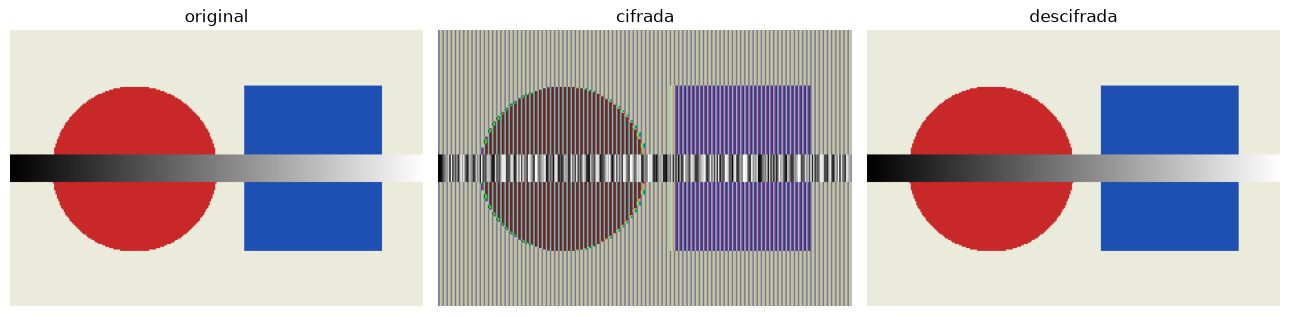

In [9]:
# imagen de prueba: fondo claro, un círculo, un rectángulo y un degradado
alto, ancho = 200, 300
img = np.full((alto, ancho, 3), (235, 235, 220), dtype=np.uint8)
y, x = np.ogrid[:alto, :ancho]
img[(y - 100) ** 2 + (x - 90) ** 2 < 60 ** 2] = (200, 40, 40)
img[40:160, 170:270] = (30, 80, 180)
img[90:110, :] = np.linspace(0, 255, ancho, dtype=np.uint8)[:, None]

print("det(K3) =", determinante(K3), "| mod 256 =", determinante(K3) % 256)
cifrada = cifrar_imagen(img, Matrix(K3))
descifrada = descifrar_imagen(cifrada, Matrix(K3), ancho=ancho)
print("¿descifrada idéntica a la original?", np.array_equal(img, descifrada))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, im, titulo in zip(ax, (img, cifrada, descifrada), ("original", "cifrada", "descifrada")):
    a.imshow(im)
    a.set_title(titulo)
    a.axis("off")
plt.tight_layout()
plt.show()

### ¿Qué le pasa a cada píxel?

Tomemos tres píxeles seguidos dentro del círculo rojo (fila 60, columnas 90 a 92). Los tres valen $(200, 40, 40)$. Se cifra cada canal por separado: el vector de rojos $(200, 200, 200)$, el de verdes $(40, 40, 40)$ y el de azules $(40, 40, 40)$.

rojo : K·[200, 200, 200] = [6200, 7800, 10400] ≡ [56, 120, 160] (mod 256)
verde: K·[40, 40, 40] = [1240, 1560, 2080] ≡ [216, 24, 32] (mod 256)
azul : K·[40, 40, 40] = [1240, 1560, 2080] ≡ [216, 24, 32] (mod 256)
originales (R, G, B): [[200, 40, 40], [200, 40, 40], [200, 40, 40]]
cifrados   (R, G, B): [[56, 216, 216], [120, 24, 24], [160, 32, 32]]


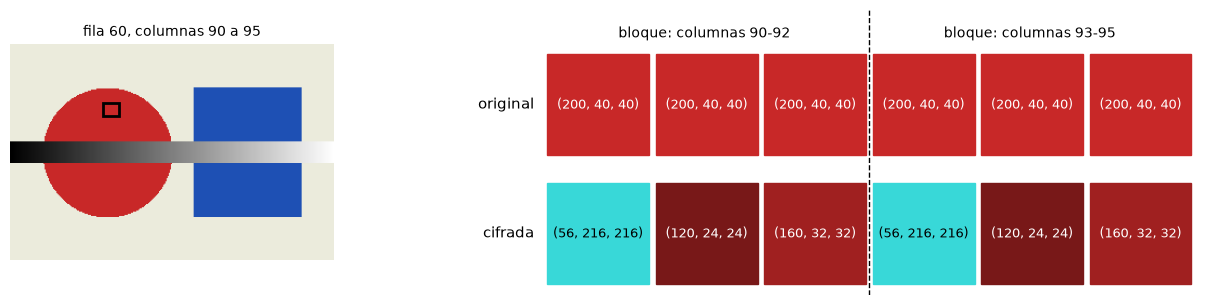

In [10]:
# Qué le pasa a un bloque de píxeles: tres píxeles del círculo rojo (fila 60, columnas 90 a 92)
from imagen import explicar_bloque

b = explicar_bloque(img, Matrix(K3), 60, 90)
for nombre, c in zip(("rojo", "verde", "azul"), b["canales"]):
    print(f"{nombre:5}: K·{c['p']} = {c['Kp']} ≡ {c['c']} (mod 256)")
print("originales (R, G, B):", b["original"])
print("cifrados   (R, G, B):", b["cifrado"])

# figura: seis píxeles seguidos (dos bloques) antes y después de cifrar
fila, columnas = 60, range(90, 96)
fig = plt.figure(figsize=(12, 3.4))
ax0 = fig.add_axes([0.0, 0.08, 0.27, 0.84])
ax0.imshow(img)
ax0.add_patch(plt.Rectangle((86, 54), 14, 12, fill=False, ec="black", lw=2))
ax0.set_title("fila 60, columnas 90 a 95", fontsize=10)
ax0.axis("off")

ax1 = fig.add_axes([0.33, 0.08, 0.66, 0.84])
for k, (im, etiqueta) in enumerate(((img, "original"), (cifrada, "cifrada"))):
    y = 1.15 - 1.15 * k
    for i, x in enumerate(columnas):
        color = im[fila, x].astype(int)
        ax1.add_patch(plt.Rectangle((i, y), 0.94, 0.9, color=color / 255))
        claro = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2] > 140
        ax1.text(i + 0.47, y + 0.45, "({}, {}, {})".format(*color), ha="center", va="center",
                 fontsize=9, color="black" if claro else "white")
    ax1.text(-0.12, y + 0.45, etiqueta, ha="right", va="center", fontsize=11)
for j, texto in enumerate(("bloque: columnas 90-92", "bloque: columnas 93-95")):
    ax1.text(3 * j + 1.45, 2.2, texto, ha="center", fontsize=10)
ax1.axvline(2.97, color="black", lw=1, ls="--")
ax1.set_xlim(-1.3, 6)
ax1.set_ylim(-0.1, 2.45)
ax1.axis("off")
fig.savefig("figuras/pixeles.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

**La matriz cambia el color, no el lugar del píxel.** Cada píxel cifrado sigue en la misma fila y columna, pero con otros valores de $R, G, B$. Cada valor nuevo mezcla los tres vecinos del bloque en ese canal (el rojo nuevo de la columna 91 es $13 \cdot 200 + 16 \cdot 200 + 10 \cdot 200 = 7800 \equiv 120$), y los canales no se mezclan entre sí. El bloque siguiente (columnas 93 a 95) es idéntico, así que se cifra idéntico: por eso en la imagen cifrada de arriba se sigue viendo el círculo.

La imagen se recupera píxel a píxel, pero en la cifrada **todavía se ven las figuras**: una zona de un solo color da siempre el mismo bloque y por lo tanto el mismo bloque cifrado. El cifrado cambia los colores pero no esconde la forma.

---

## 7. Encadenar bloques

Para que bloques iguales no den cifrados iguales, cada bloque se suma con el cifrado anterior antes de multiplicar:

$$c_i = K\,(p_i + c_{i-1}) \pmod{256}, \qquad c_0 = 0$$

Para descifrar se despeja $p_i$:

$$p_i = K^{-1} c_i - c_{i-1} \pmod{256}$$

¿descifrada idéntica a la original? True


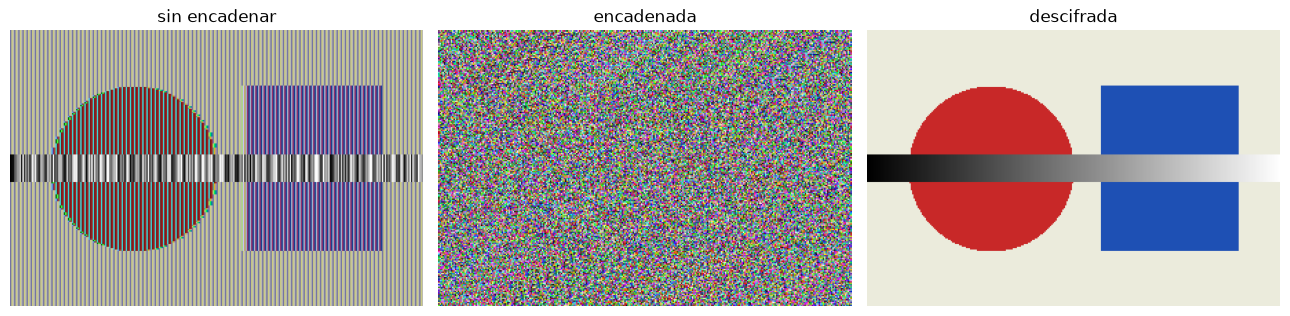

In [11]:
from imagen import cifrar_imagen_encadenado, descifrar_imagen_encadenado

encadenada = cifrar_imagen_encadenado(img, Matrix(K3))
descifrada_enc = descifrar_imagen_encadenado(encadenada, Matrix(K3), ancho=ancho)
print("¿descifrada idéntica a la original?", np.array_equal(img, descifrada_enc))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, im, titulo in zip(ax, (cifrada, encadenada, descifrada_enc), ("sin encadenar", "encadenada", "descifrada")):
    a.imshow(im)
    a.set_title(titulo)
    a.axis("off")
plt.tight_layout()
plt.show()

Encadenando ya no se ven las figuras y la imagen se sigue recuperando igual.

Pero el cifrado sigue siendo lineal. Si el atacante conoce algunos píxeles $p_i$ y ve los cifrados, también conoce cada $c_{i-1}$, entonces arma $C = K\,(P + C_{\text{ant}})$ y despeja $K = C\,(P + C_{\text{ant}})^{-1}$:

In [12]:
# primera fila del canal rojo: el atacante conoce los primeros bloques de la imagen original
p = [int(v) for v in img[0, :, 0]]
c = [int(v) for v in encadenada[0, :, 0]]
bloques_p = [list(p[i:i + 3]) for i in range(0, 30, 3)]
bloques_c = [list(c[i:i + 3]) for i in range(0, 30, 3)]
bloques_ant = [[0, 0, 0]] + bloques_c[:-1]  # c_0 = 0

for cols in combinations(range(1, 10), 3):
    # columnas de P + C_ant y de C
    S = [[(bloques_p[j][i] + bloques_ant[j][i]) % 256 for j in cols] for i in range(3)]
    if determinante(S) % 2 == 1:
        break

C = [[bloques_c[j][i] for j in cols] for i in range(3)]
K_recuperada = multiplicar_mod(C, inversa_mod(S, 256), 256)
print("bloques", cols, "| K =", K_recuperada)
print("¿es la clave original?", K_recuperada == K3)

bloques (1, 2, 3) | K = [[6, 24, 1], [13, 16, 10], [20, 17, 15]]
¿es la clave original? True


Encadenar esconde los patrones, pero no arregla la debilidad de fondo: la clave sale igual resolviendo un sistema lineal.

---

## Conclusiones

1. El cifrado de Hill es álgebra lineal directa: cifrar es multiplicar por una matriz y descifrar es multiplicar por su inversa.
2. Módulo $m$ no basta $\det K \neq 0$, se necesita $\text{mcd}(\det K, m) = 1$.
3. Por ser lineal, con $n^2$ letras conocidas la clave sale resolviendo $K = C P^{-1}$.
4. Bloques iguales dan cifrados iguales, por eso en la imagen se siguen viendo las figuras. Encadenar los bloques lo arregla, pero la clave se sigue recuperando con $K = C\,(P + C_{\text{ant}})^{-1}$.